# Overfitting, Underfitting y Generalización

Hasta aquí asumimos que más capacidad es mejor. No lo es. Hay tres situaciones:

- **Underfitting (high bias):** el modelo es muy simple y ni siquiera aprende los datos de entrenamiento. Ejemplo: una recta para datos con curva.
- **Buen ajuste:** el modelo captura el patrón real sin memorizar el ruido. 
- **Overfitting (high variance):** el modelo es muy flexible y memoriza hasta el ruido de los datos de entrenamiento. Error casi cero en train, pero falla con datos nuevos.

**Generalización** es la palabra clave: lo único que importa es rendir bien con datos que el modelo nunca vio. La brecha entre error de train y error de test es el síntoma medible del overfitting.

### Demo 1: overfitting en regresión lineal

Datos 1D con una curva real más ruido (como los del Lab 05). Ajustamos el mismo dataset con tres capacidades: recta (grado 1), cuadrática (grado 2) y grado 12. La gráfica muestra quién sigue la curva y quién persigue cada punto ruidoso.

Grado  1: error de train = 1.749
Grado  2: error de train = 0.413
Grado 12: error de train = 0.279


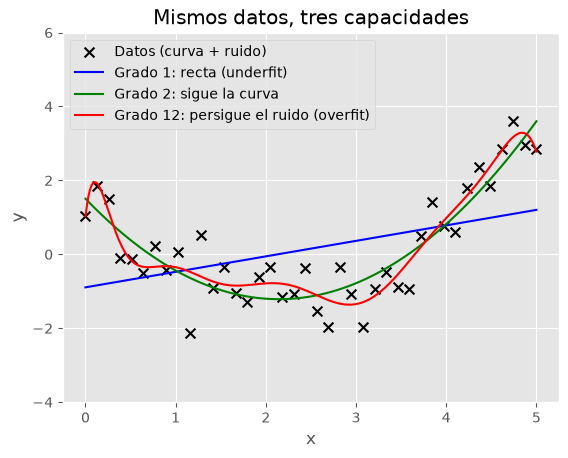

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

# Datos 1D con curva real + ruido
rng = np.random.default_rng(11)
x = np.linspace(0, 5, 40)
y = 0.5 * x ** 2 - 2 * x + 1 + rng.normal(0, 0.8, 40)

# Paso 1: Ajustar grados 1 (underfit), 2 (bueno) y 12 (overfit)
coefs = {}
for d in [1, 2, 12]:
    p = np.polyfit(x, y, d)
    coefs[d] = p
    err = float(((np.polyval(p, x) - y) ** 2).mean())
    print(f"Grado {d:2d}: error de train = {err:.3f}")

# Gráfica de los 3 ajustes sobre los mismos datos
xs = np.linspace(0, 5, 300)
plt.scatter(x, y, marker='x', c='k', s=50, label='Datos (curva + ruido)')
plt.plot(xs, np.polyval(coefs[1], xs), c='b', label='Grado 1: recta (underfit)')
plt.plot(xs, np.polyval(coefs[2], xs), c='g', label='Grado 2: sigue la curva')
plt.plot(xs, np.polyval(coefs[12], xs), c='r', label='Grado 12: persigue el ruido (overfit)')
plt.title("Mismos datos, tres capacidades")
plt.xlabel("x")
plt.ylabel("y")
plt.ylim(-4, 6)
plt.legend()
plt.show()

### Demo 2: overfitting en clasificación (LR)

Lo mismo pero con fronteras: anillo microchip del Lab 06 (buenos al centro, defectuosos alrededor). Entrenamos regresión logística con features polinomiales de grado 1 (recta: underfit), grado 2 (círculo: punto bueno) y grado 8 (frontera enredada: overfit). La gráfica muestra cómo la frontera de grado 8 se contorsiona para abrazar cada punto.

Grado 1: exactitud en train = 58%
Grado 2: exactitud en train = 100%
Grado 8: exactitud en train = 100%


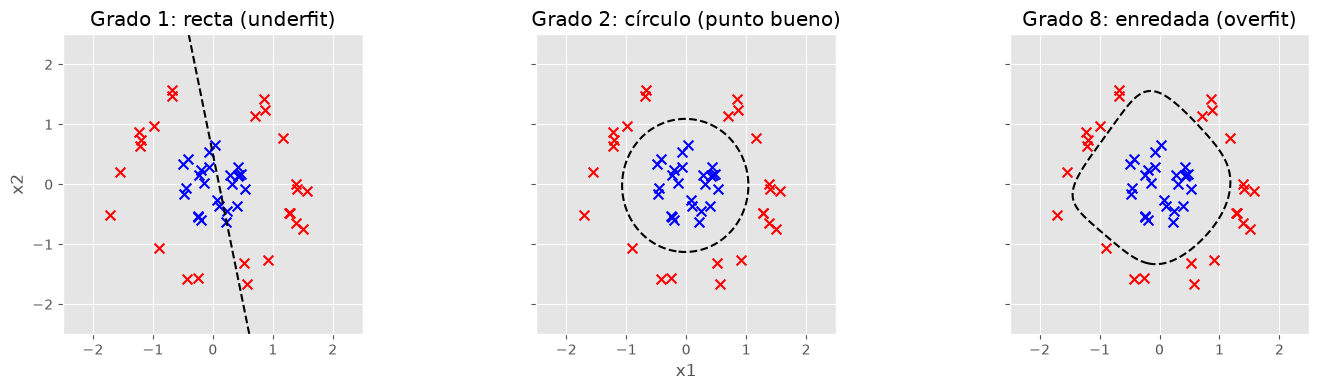

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

# Anillo: buenos al centro, defectuosos alrededor
rng = np.random.default_rng(5)
n = 25
th = rng.uniform(0, 2 * np.pi, n)
good = np.column_stack([rng.normal(0.5, 0.18, n) * np.cos(th), rng.normal(0.5, 0.18, n) * np.sin(th)])
th2 = rng.uniform(0, 2 * np.pi, n)
bad = np.column_stack([rng.normal(1.5, 0.18, n) * np.cos(th2), rng.normal(1.5, 0.18, n) * np.sin(th2)])
X = np.vstack([good, bad])
y = np.array([0] * n + [1] * n)

def poly_features(X, d):
    """Expande a potencias hasta grado d (truco del Lab 05)."""
    cols = [np.ones(len(X))]
    for i in range(1, d + 1):
        for j in range(i + 1):
            cols.append((X[:, 0] ** (i - j)) * (X[:, 1] ** j))
    return np.column_stack(cols)

def train_logistic(X, y, alpha, iters):
    """GD logístico con Z-score interno (regla del Lab 05)."""
    mu, sg = X[:, 1:].mean(axis=0), X[:, 1:].std(axis=0)
    Xn = np.column_stack([np.ones(len(X)), (X[:, 1:] - mu) / sg])
    w = np.zeros(Xn.shape[1])
    for _ in range(iters):
        w -= alpha * (Xn.T @ (sigmoid(Xn @ w) - y)) / len(y)
    return w, mu, sg

# Paso 2: Entrenar grados 1, 2 y 8 sobre el mismo anillo
modelos = {}
for d, alpha, iters in [(1, 0.5, 3000), (2, 0.5, 5000), (8, 0.1, 8000)]:
    P = poly_features(X, d)
    w, mu, sg = train_logistic(P, y, alpha, iters)
    Pn = np.column_stack([np.ones(len(X)), (P[:, 1:] - mu) / sg])
    acc = float((((sigmoid(Pn @ w) >= 0.5).astype(int)) == y).mean())
    modelos[d] = (w, mu, sg)
    print(f"Grado {d}: exactitud en train = {acc:.0%}")

# Gráfica de las 3 fronteras con contornos
g = np.linspace(-2.5, 2.5, 200)
G1, G2 = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, d, title in zip(axes, [1, 2, 8],
                         ["Grado 1: recta (underfit)", "Grado 2: círculo (punto bueno)",
                          "Grado 8: enredada (overfit)"]):
    w, mu, sg = modelos[d]
    Pm = poly_features(np.column_stack([G1.ravel(), G2.ravel()]), d)
    Pn = np.column_stack([np.ones(len(Pm)), (Pm[:, 1:] - mu) / sg])
    Z = sigmoid(Pn @ w).reshape(G1.shape)
    ax.scatter(good[:, 0], good[:, 1], marker='x', c='b', s=50)
    ax.scatter(bad[:, 0], bad[:, 1], marker='x', c='r', s=50)
    ax.contour(G1, G2, Z, levels=[0.5], colors='k', linestyles='--')
    ax.set_title(title)
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_aspect('equal')
axes[1].set_xlabel("x1")
axes[0].set_ylabel("x2")
plt.tight_layout()
plt.show()

### Cierre

- High bias = modelo simple que ni entrena bien; high variance = modelo flexible que memoriza.
- Generalizar es rendir con datos nuevos; la brecha train-test lo mide.
- Más capacidad no es mejor: el punto bueno está en medio.
- ¿Y si ya hay overfitting? La salida es la **regularización**: penalizar pesos grandes (Lab 10).